In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread('images/dog.jpg')

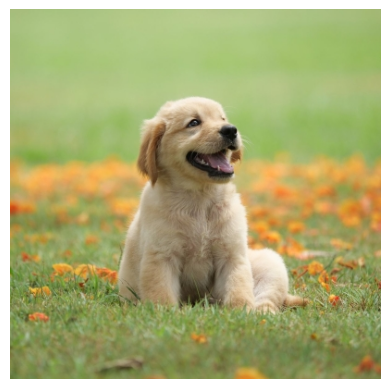

In [3]:
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Image Translation

In [4]:
import numpy as np

quarter_width, quarter_height = img.shape[1]//2, img.shape[0]//2
T= np.float32([[1,0,quarter_width],[0,1,quarter_height]])
T

array([[  1.,   0., 200.],
       [  0.,   1., 200.]], dtype=float32)

#cv2.waitKey(0)
#cv2.destroyAllWindows()
# this will needed in VS code

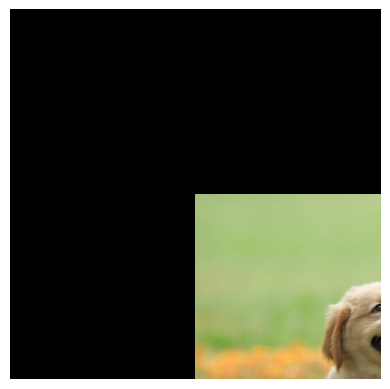

In [5]:
translated_img = cv2.warpAffine(img,T,(img.shape[1],img.shape[0])) ## T is translation, next shape is new size of image
plt.imshow(cv2.cvtColor(translated_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

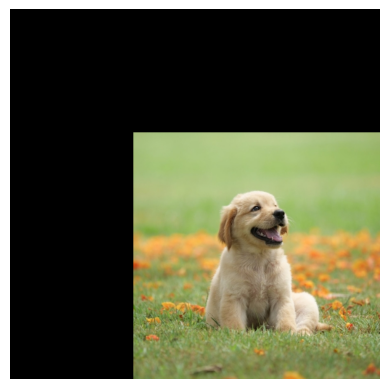

In [6]:
translated_img = cv2.warpAffine(img, T, (600, 600))

plt.imshow(cv2.cvtColor(translated_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()
#cv2.waitKey(0)
#cv2.destroyAllWindows()


In [20]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


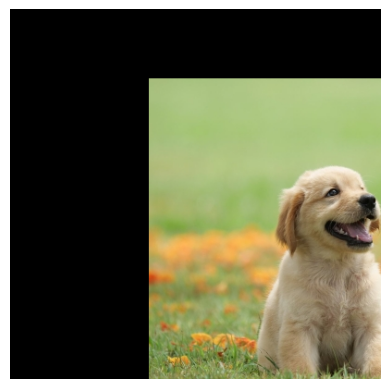

In [7]:
T= np.float32([[1,0,150],[0,1,75]])
translated_img = cv2.warpAffine(img,T,(img.shape[1],img.shape[0])) ## T is translation
plt.imshow(cv2.cvtColor(translated_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

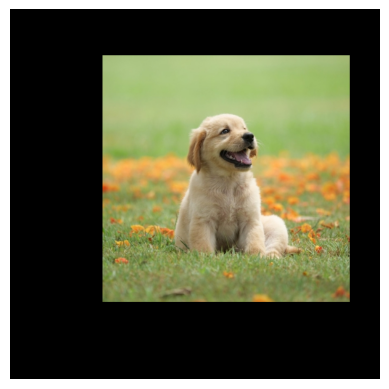

In [8]:
T= np.float32([[1,0,150],[0,1,75]])   ## T is translation, next shape is new size of image
translated_img = cv2.warpAffine(img, T, (600, 600))

plt.imshow(cv2.cvtColor(translated_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Image Rotation

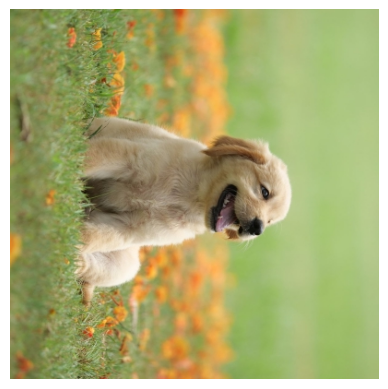

In [9]:
img_90 = cv2.rotate(img,cv2.ROTATE_90_CLOCKWISE)
plt.imshow(cv2.cvtColor(img_90, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Rotation :180 degree rotation

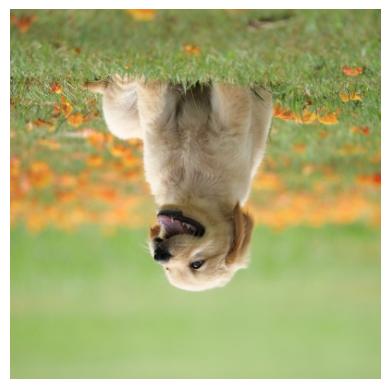

In [10]:
img_180 = cv2.rotate(img,cv2.ROTATE_180)
plt.imshow(cv2.cvtColor(img_180, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Rotation :90 degree rotation

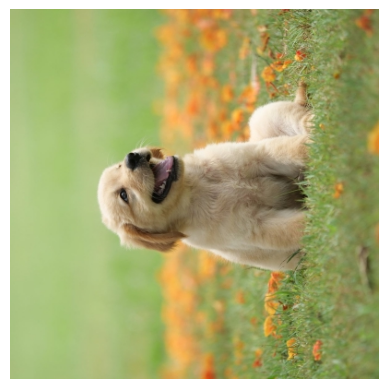

In [11]:
img_90 = cv2.rotate(img,cv2.ROTATE_90_COUNTERCLOCKWISE)
plt.imshow(cv2.cvtColor(img_90, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Rotation : 30 degree rotation

In [12]:
center = img.shape[0]// 2, img.shape[0]// 2


In [13]:
center

(200, 200)

In [14]:
angle = 30

In [15]:
R = cv2.getRotationMatrix2D(center,angle,1.0) ## Rotation matrix , scale

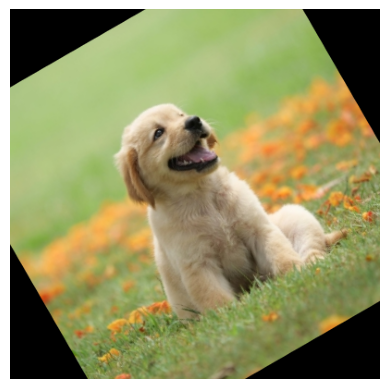

In [16]:
rotated_img = cv2.warpAffine(img,R,(400,400))
rotated_img_rgb = cv2.cvtColor(rotated_img, cv2.COLOR_BGR2RGB)
plt.imshow(rotated_img_rgb)   # Display the rotated image
plt.axis('off')
plt.show()

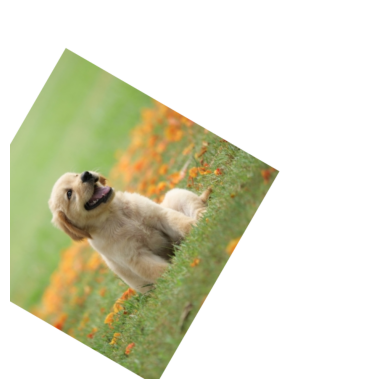

In [17]:
R = cv2.getRotationMatrix2D((300,300),60,1.0)
rotated_img = cv2.warpAffine(img,R,(600,600), borderValue=(255, 255, 255)) # 600 is new size  ,  rotated image are filled with white.
plt.imshow(cv2.cvtColor(rotated_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## alternative method for BG color white using masking

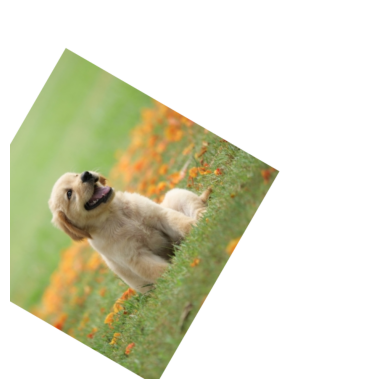

In [18]:
mask = np.all(rotated_img == (0, 0, 0), axis=-1) # mask
rotated_img[mask] = [255, 255, 255] # masking matching
plt.imshow(cv2.cvtColor(rotated_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Image Resampling/Rescaling/Resizing

#Resizing

In [19]:
## resizing
img_new = cv2.resize(img,(500,500))


In [20]:
img_new.shape

(500, 500, 3)

In [21]:
cv2.imshow("New Image",img_new)

In [23]:
img_new = cv2.resize(img,(700,500))
cv2_imshow(img_new)

NameError: name 'cv2_imshow' is not defined

#Rescaling

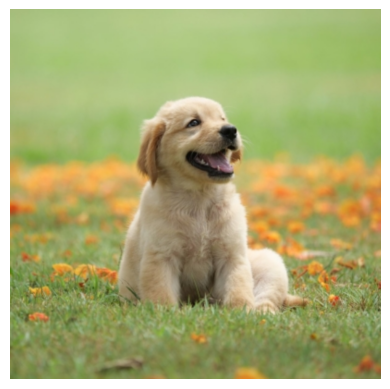

In [24]:

img_new_2 = cv2.resize(img, None, fx=1.5, fy=1.5)

plt.imshow(cv2.cvtColor(img_new_2, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Transformation using pillow (PIL library)

In [25]:
from PIL import Image

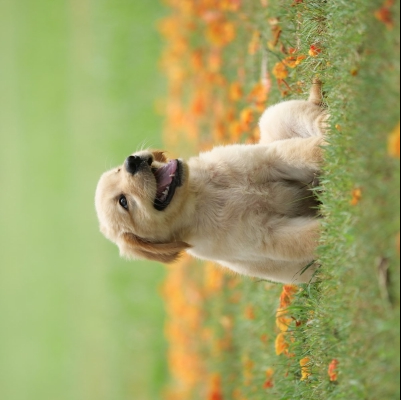

In [26]:
img_pil = Image.open('images/dog.jpg')
img_pil.rotate(90)

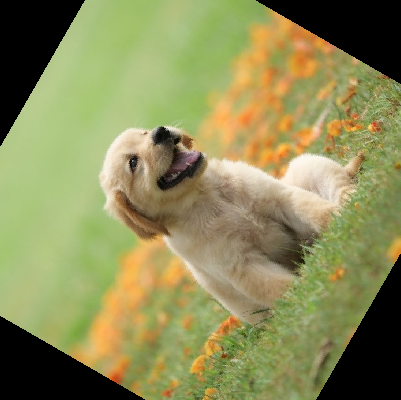

In [27]:
img_pil.rotate(60) #rotation


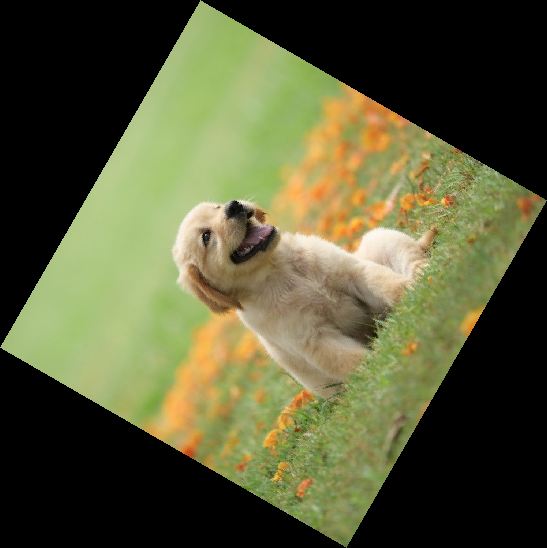

In [28]:
img_pil.rotate(60,expand=True)          # expand mean to fit the particular image

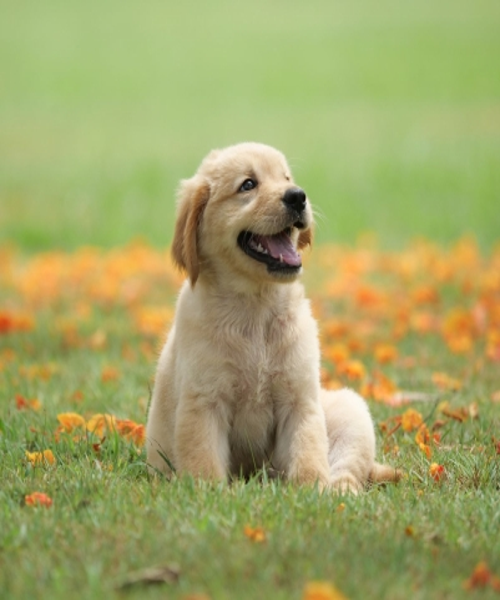

In [29]:
img_pil.resize((500,600))           # resizing

## Image Resizing Using Scikit-image

In [32]:
from skimage.transform import resize

In [33]:
img_rgb = plt.imread('images/dog.jpg')
img_resize = resize(img_rgb,(500,400))
img_resize.shape

(500, 400, 3)

Text(0.5, 1.0, 'Resized')

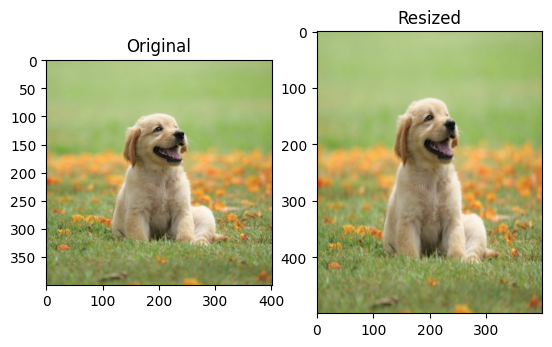

In [34]:
plt.subplot(121)
plt.imshow(img_rgb);plt.title('Original')
plt.subplot(122)
plt.imshow(img_resize);plt.title('Resized')
#

## Image Flipping using img_rgb

In [35]:
img_rgb = plt.imread('images/dog.jpg')

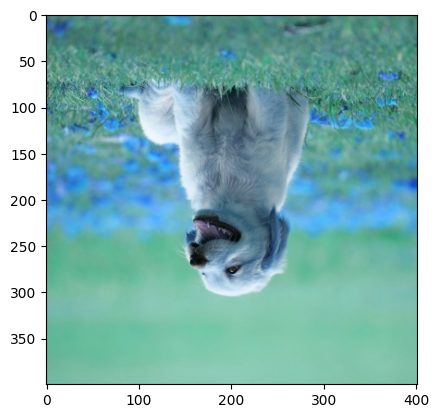

In [36]:
new_img= np.flip(img_rgb)
plt.imshow(new_img)

## using cv2 for image flipping

In [37]:
img_rgb = cv2.cvtColor(img_rgb,cv2.COLOR_RGB2BGR)


img_ver= cv2.flip(img_rgb,0) ## vertical flipping


img_hor= cv2.flip(img_rgb,1) ## horizonal flipping


img_diagonal = cv2.flip(img_rgb,-1) ## diagonal flipping


Text(0.5, 1.0, 'Diagonal')

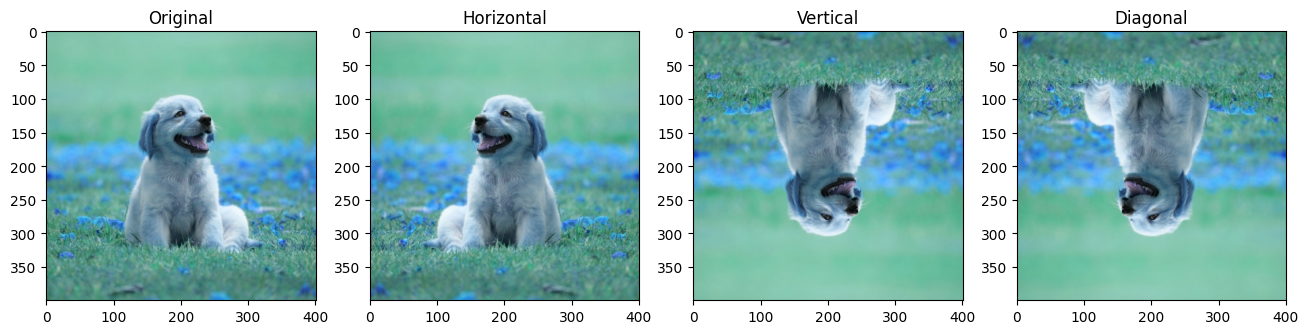

In [38]:
plt.figure(figsize=(16,9))

plt.subplot(141)
plt.imshow(img_rgb);plt.title('Original')

plt.subplot(142)
plt.imshow(img_hor);plt.title('Horizontal')

plt.subplot(143)
plt.imshow(img_ver);plt.title('Vertical')

plt.subplot(144)
plt.imshow(img_diagonal);plt.title('Diagonal') # top bottom left right

## Image Cropping (not have function)
just only can use array

In [39]:
height,width = img_rgb.shape[0],img_rgb.shape[1]


In [40]:
startRow = int(height*.25)
startCol = int(width*.25)
endRow = int(height*.85)
endCol = int(width*.85)


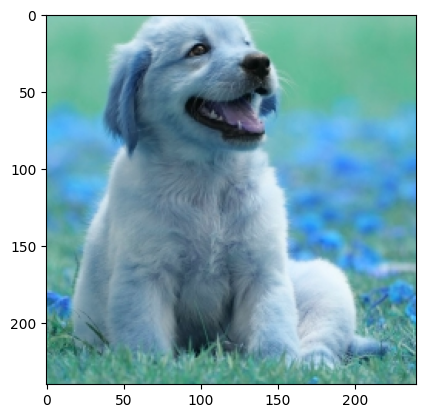

In [41]:
croppedImg = img_rgb[startRow:endRow,startCol:endCol]
plt.imshow(croppedImg)

In [42]:
croppedImg.shape

(240, 240, 3)